In [1]:
import sys
from pathlib import Path

# Tell Python where the pulse library (the python folder) is.
# This looks upward from the notebook's folder until it finds the project,
# so it works wherever in the project your notebook is.
here = Path.cwd().resolve()
REPO = next((p for p in [here, *here.parents] if (p / "python" / "pulse_io.py").exists()), None)
assert REPO, "Start Jupyter from inside the NSDF-Data folder."
sys.path.insert(0, str(REPO / "python"))

from nsdf_dark_matter.idx import load_all_data
import pulse_io as pio

# Open the dump you downloaded.
cdms = load_all_data(str(Path.home() / "idx" / "07221203_2025_F0001"))

# Take every trace from detector 0, channel 0, into one table.
ids, pulses = pio.load_channel_batch(
    cdms, pio.filter_by_detector(cdms.get_detector_ids(), 0), 0)

print(pulses.shape)

(1517, 4096)


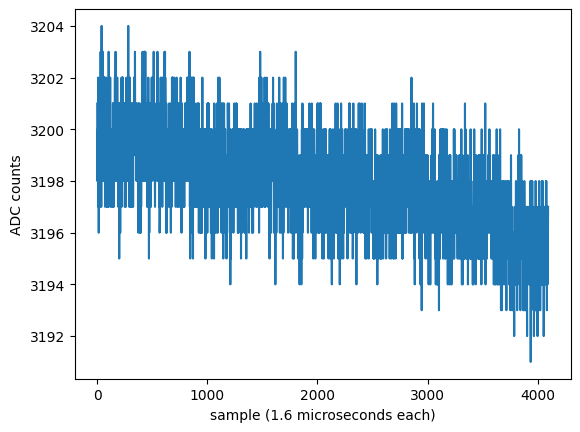

In [3]:
import matplotlib.pyplot as plt

plt.plot(pulses[1])
plt.xlabel("sample (1.6 microseconds each)")
plt.ylabel("ADC counts")
plt.show()

In [4]:
from dataclasses import replace
from pulse_config import DEFAULT_CONFIG
import pulse_quantities as pq
import pulse_cuts as pc
import numpy as np

c500 = replace(DEFAULT_CONFIG, pretrigger_samples=500)
quiet = pc.excursion_band(pulses, c500) & (np.log10(pq.bstd(pulses)) < 0.5)
print(quiet.sum())

179


Above, we loaded the data from series `07221203_2025` and looked at a trace. In the process we've loaded some libraries in the Python code so that we have some useful functions for managing the data. The trace above is just one event that has been selected. 